# Naive Bayes — Chemical Carcinogenicity Prediction
**ITCS 3162 | Samip Khanal**

Predict `is_carcinogenic` using the team's existing chemical-grouped training/test split. This notebook evaluates **Gaussian Naive Bayes** against a majority-class baseline. It does not re-split the data, so results are comparable to the other team models. The source split was prepared by the team; this notebook does not independently verify chemical IDs.

## 1. Imports and data loading
Run this notebook from the repository root or from `notebooks/`. No raw data preparation is needed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report)

root = Path.cwd()
if not (root / 'data' / 'training' / 'X_train.csv').exists():
    root = root.parent
folder = root / 'data' / 'training'
assert folder.exists(), 'Run from the repository root or notebooks directory.'
X_train = pd.read_csv(folder / 'X_train.csv')
X_test = pd.read_csv(folder / 'X_test.csv')
y_train = pd.read_csv(folder / 'y_train.csv')['is_carcinogenic']
y_test = pd.read_csv(folder / 'y_test.csv')['is_carcinogenic']
assert list(X_train.columns) == list(X_test.columns)
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)
assert not X_train.isna().any().any() and not X_test.isna().any().any()
print(f'Train: {X_train.shape}, Test: {X_test.shape}')
print('Train class counts:', y_train.value_counts().sort_index().to_dict())
print('Test class counts:', y_test.value_counts().sort_index().to_dict())

Train: (5892, 364), Test: (1353, 364)
Train class counts: {0: 3471, 1: 2421}
Test class counts: {0: 765, 1: 588}


## 2. Train the models
GaussianNB supports continuous features and one-hot encoded indicators. Its feature-independence and Gaussian distribution assumptions are limitations worth discussing.

In [2]:
model = GaussianNB()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_score = model.predict_proba(X_test)[:, list(model.classes_).index(1)]

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)
base_score = baseline.predict_proba(X_test)[:, list(baseline.classes_).index(1)]

## 3. Evaluate performance
**Recall for class 1** is especially important: it measures the fraction of carcinogenic records identified. ROC-AUC measures ranking discrimination, not classification accuracy.

In [3]:
def evaluate(name, predictions, scores):
    return {'model': name,
            'accuracy': accuracy_score(y_test, predictions),
            'precision': precision_score(y_test, predictions, zero_division=0),
            'recall': recall_score(y_test, predictions, zero_division=0),
            'f1': f1_score(y_test, predictions, zero_division=0),
            'roc_auc': roc_auc_score(y_test, scores)}

results = pd.DataFrame([evaluate('Gaussian Naive Bayes', y_pred, y_score),
                        evaluate('Majority-class baseline', base_pred, base_score)])
print(results.round(4).to_string(index=False))
print('\nNaive Bayes classification report:')
print(classification_report(y_test, y_pred, target_names=['Non-carcinogenic (0)', 'Carcinogenic (1)'], zero_division=0))

                  model  accuracy  precision  recall     f1  roc_auc
   Gaussian Naive Bayes    0.6726     0.8919  0.2806 0.4269   0.8328
Majority-class baseline    0.5654     0.0000  0.0000 0.0000   0.5000

Naive Bayes classification report:
                      precision    recall  f1-score   support

Non-carcinogenic (0)       0.64      0.97      0.77       765
    Carcinogenic (1)       0.89      0.28      0.43       588

            accuracy                           0.67      1353
           macro avg       0.76      0.63      0.60      1353
        weighted avg       0.75      0.67      0.62      1353



## 4. Poster-ready charts

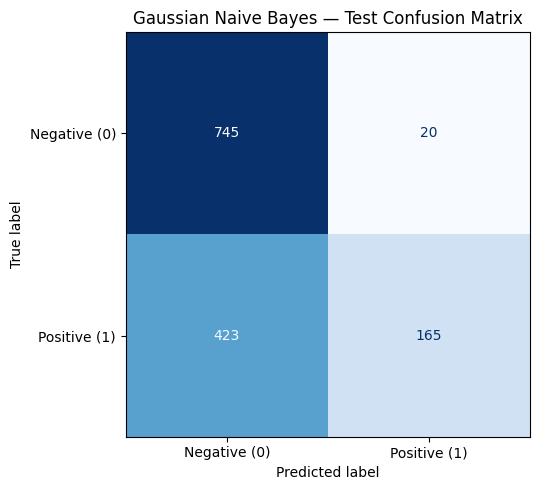

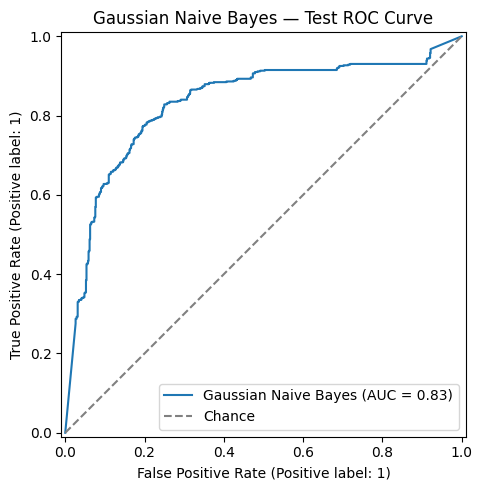

Saved results to: /mnt/data/cpdb_work/Chemical-Carcinogenicity-Prediction-main/results


In [4]:
out = root / 'results'
out.mkdir(exist_ok=True)
results.to_csv(out / 'naive_bayes_results.csv', index=False)

fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=[0, 1],
    display_labels=['Negative (0)', 'Positive (1)'], cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Gaussian Naive Bayes — Test Confusion Matrix')
fig.tight_layout()
fig.savefig(out / 'naive_bayes_confusion_matrix.png', dpi=220, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5))
RocCurveDisplay.from_predictions(y_test, y_score, name='Gaussian Naive Bayes', ax=ax)
ax.plot([0, 1], [0, 1], '--', color='gray', label='Chance')
ax.set_title('Gaussian Naive Bayes — Test ROC Curve')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(out / 'naive_bayes_roc_curve.png', dpi=220, bbox_inches='tight')
plt.show()
print('Saved results to:', out)

## 5. Interpretation and limitations
- Compare Naive Bayes with the majority-class baseline and other models using the **same held-out test set**.
- Report both recall and precision; high recall with many false positives is a tradeoff.
- GaussianNB assumes conditional feature independence and Gaussian distributions, which may be poor approximations for sparse one-hot indicators.
- Because several rows can represent related experiments, evaluation is at the **record level**, not necessarily chemical level.
- Test labels are CPDB experimental classifications, not definitive statements about human cancer risk.
- Do not tune on the test set. Any later hyperparameter search should use chemical-grouped validation folds within the training data.